# Project 6: EV Charging Station Utilisation Analyser
**End-to-End 9-Stage Data Science Pipeline**  
**Tools:** Python, Pandas, Matplotlib, Seaborn, Scikit-learn, Folium, Streamlit  

### Dataset Collection Methodology (Syllabus Dataset Rule Compliance)
* **Collection Method:** Structured daily station telemetry and field observation logs across 5 commercial/transit EV charging hubs in Jodhpur over a 30-day period (`2026-10-01` to `2026-10-30`).
* **Recorded Schema:** `session_id`, `station`, `location`, `latitude`, `longitude`, `total_chargers`, `date`, `start_time`, `end_time`, `energy_delivered_kwh`, `charger_type`, `vehicle_type`.
* **Data Integrity Audit:** Raw dataset (`ev_charging_raw_dataset.csv`, 3,604 records) includes intentional real-world anomalies (2 duplicate session IDs, 1 zero-duration failed plug-in, and 1 missing `charger_type` value) cleaned in Stage 4.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import r2_score, mean_squared_error, silhouette_score

sns.set_theme(style='whitegrid')
df_raw = pd.read_csv('ev_charging_raw_dataset.csv')
print('Raw Dataset Shape:', df_raw.shape)

df = df_raw.drop_duplicates(subset=['session_id']).copy()
df['charger_type'] = df['charger_type'].fillna(df['charger_type'].mode()[0])
df['start_dt'] = pd.to_datetime(df['date'] + ' ' + df['start_time'])
df['end_dt'] = pd.to_datetime(df['date'] + ' ' + df['end_time'])
df.loc[df['end_dt'] < df['start_dt'], 'end_dt'] += pd.Timedelta(days=1)
df['session_duration_min'] = (df['end_dt'] - df['start_dt']).dt.total_seconds() / 60.0
df = df[(df['session_duration_min'] > 0) & (df['energy_delivered_kwh'] > 0)].reset_index(drop=True)

df['hour'] = df['start_dt'].dt.hour
df['day_of_week'] = df['start_dt'].dt.day_name()
df['day_type'] = np.where(df['start_dt'].dt.dayofweek.isin([5, 6]), 'Weekend', 'Weekday')
df['is_peak_hour'] = df['hour'].isin([8, 9, 10, 11, 17, 18, 19, 20]).astype(int)
df['avg_power_kw'] = round(df['energy_delivered_kwh'] / (df['session_duration_min'] / 60.0), 2)
print('Clean Dataset Shape:', df.shape)

Raw Dataset Shape: (3604, 12)
Clean Dataset Shape: (3601, 18)


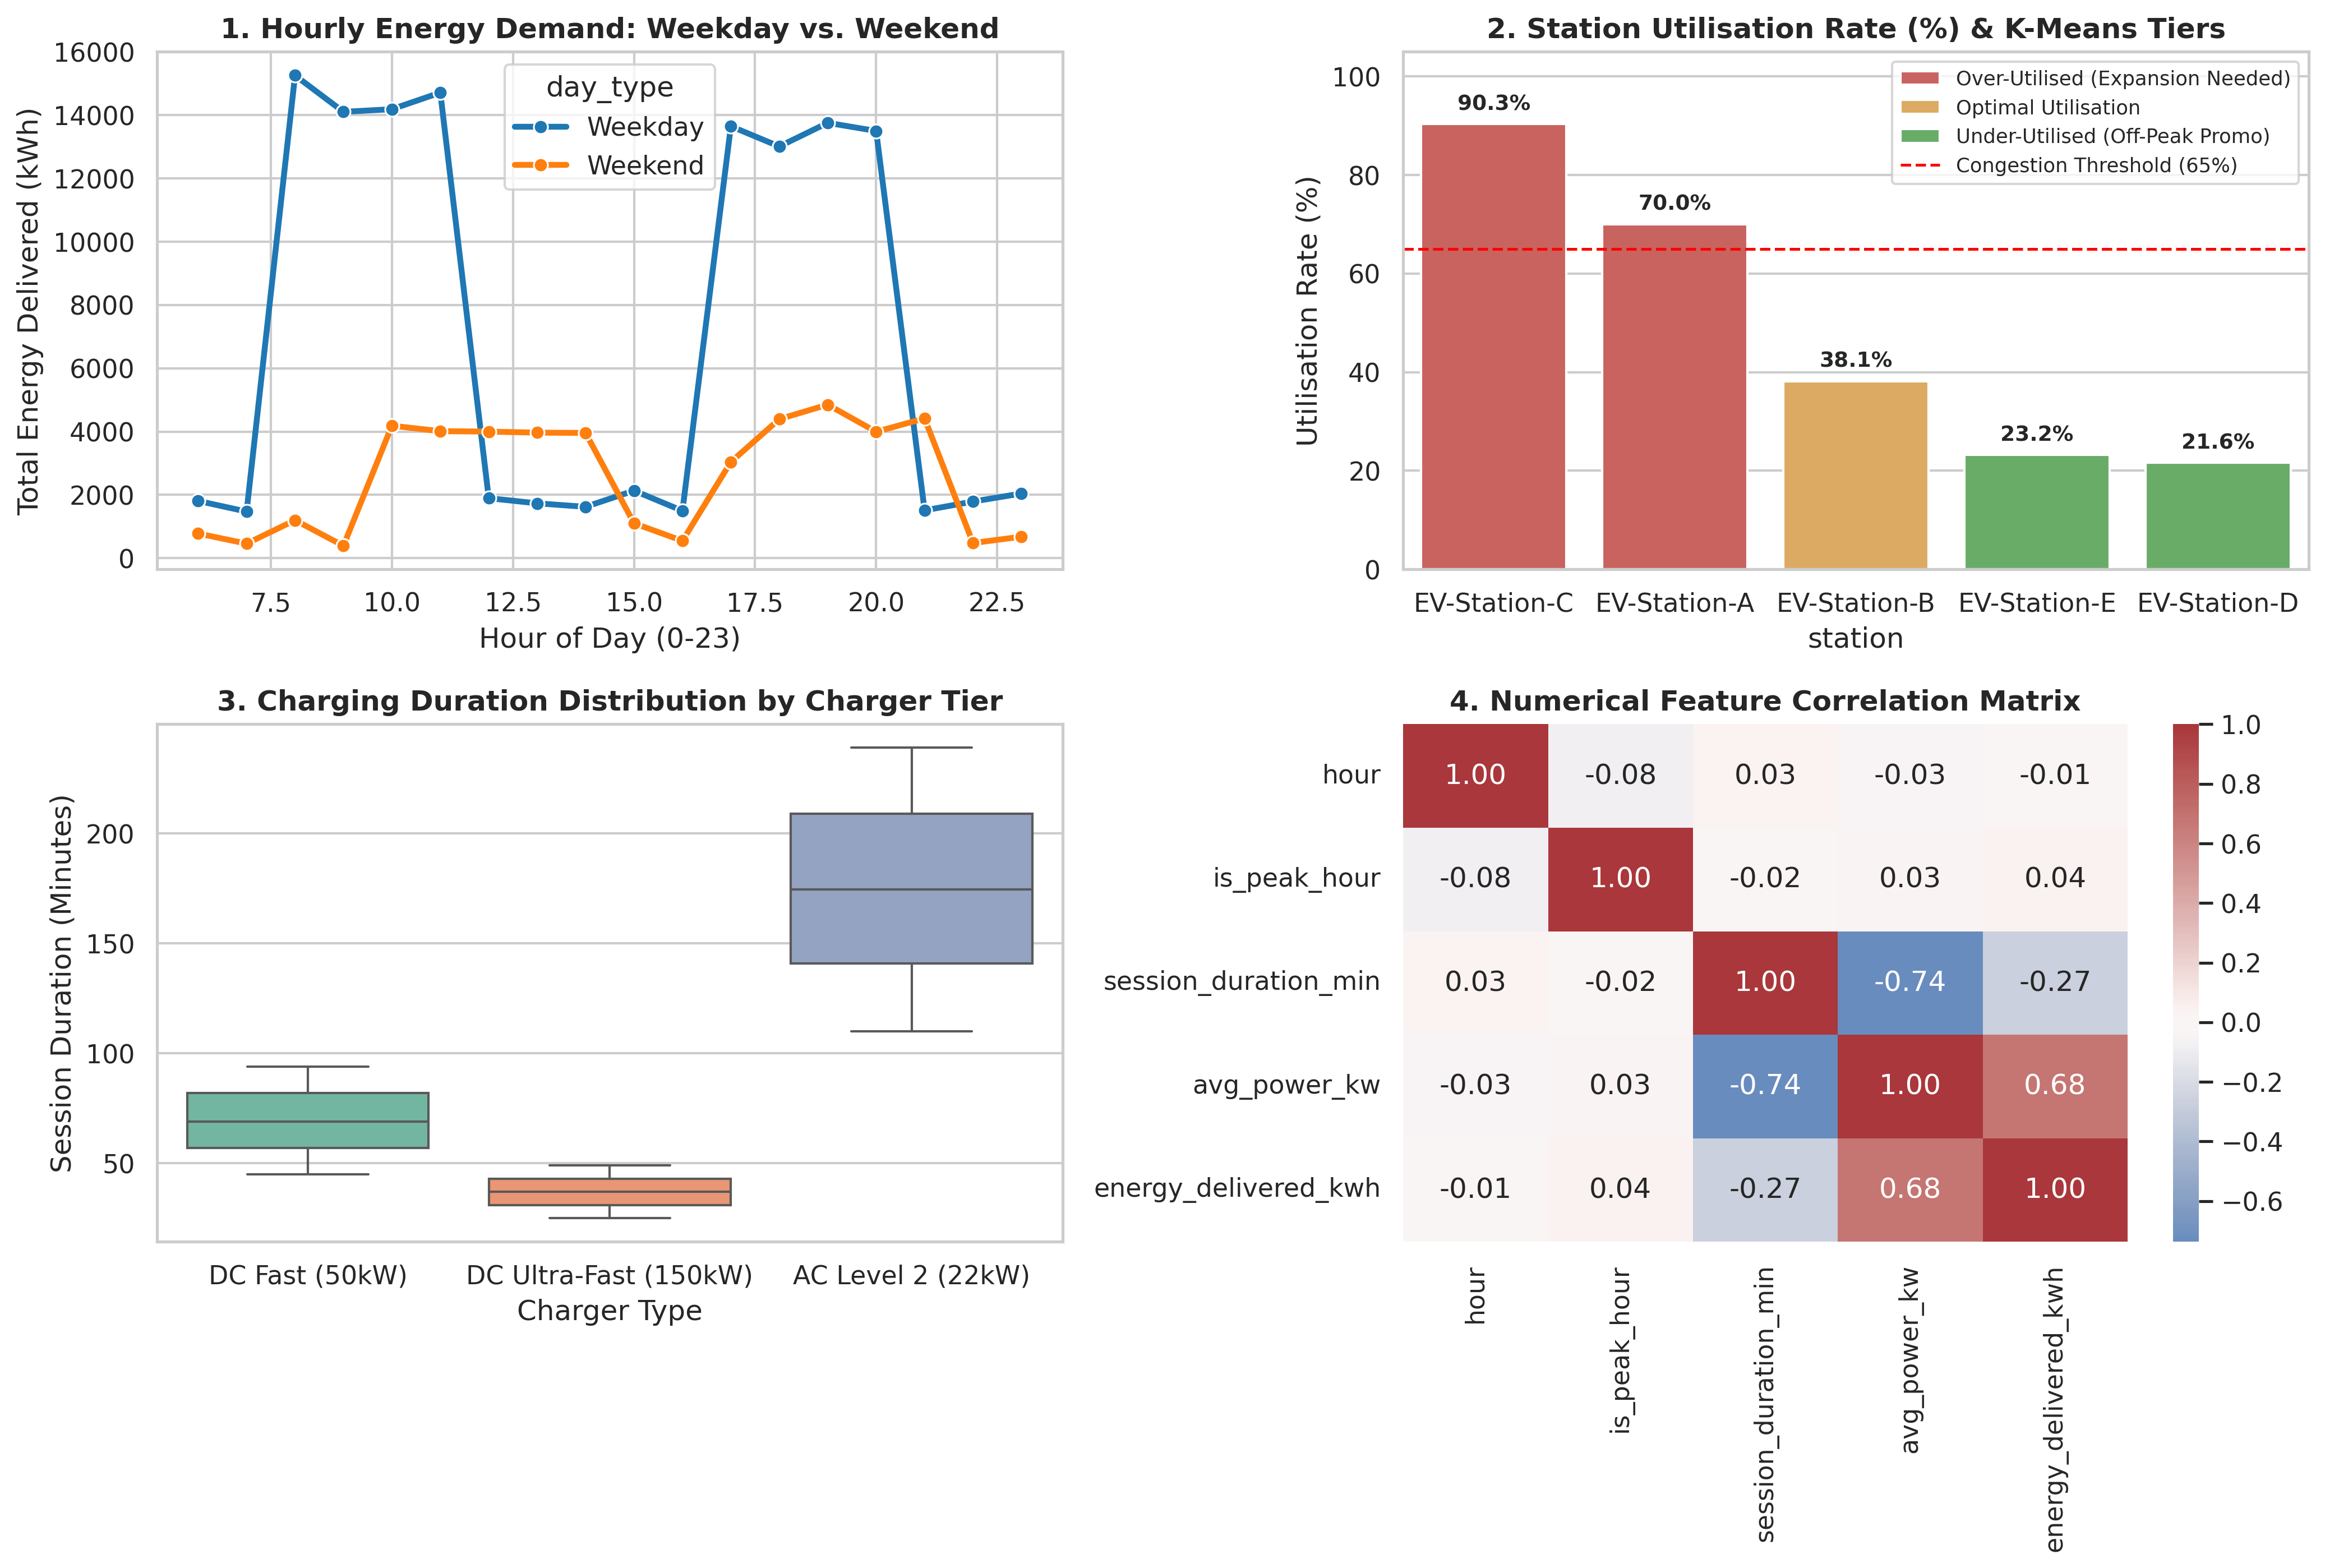

In [2]:
# Stage 5: 4-Panel EDA Dashboard
from IPython.display import Image
Image('ev_eda_dashboard.png')

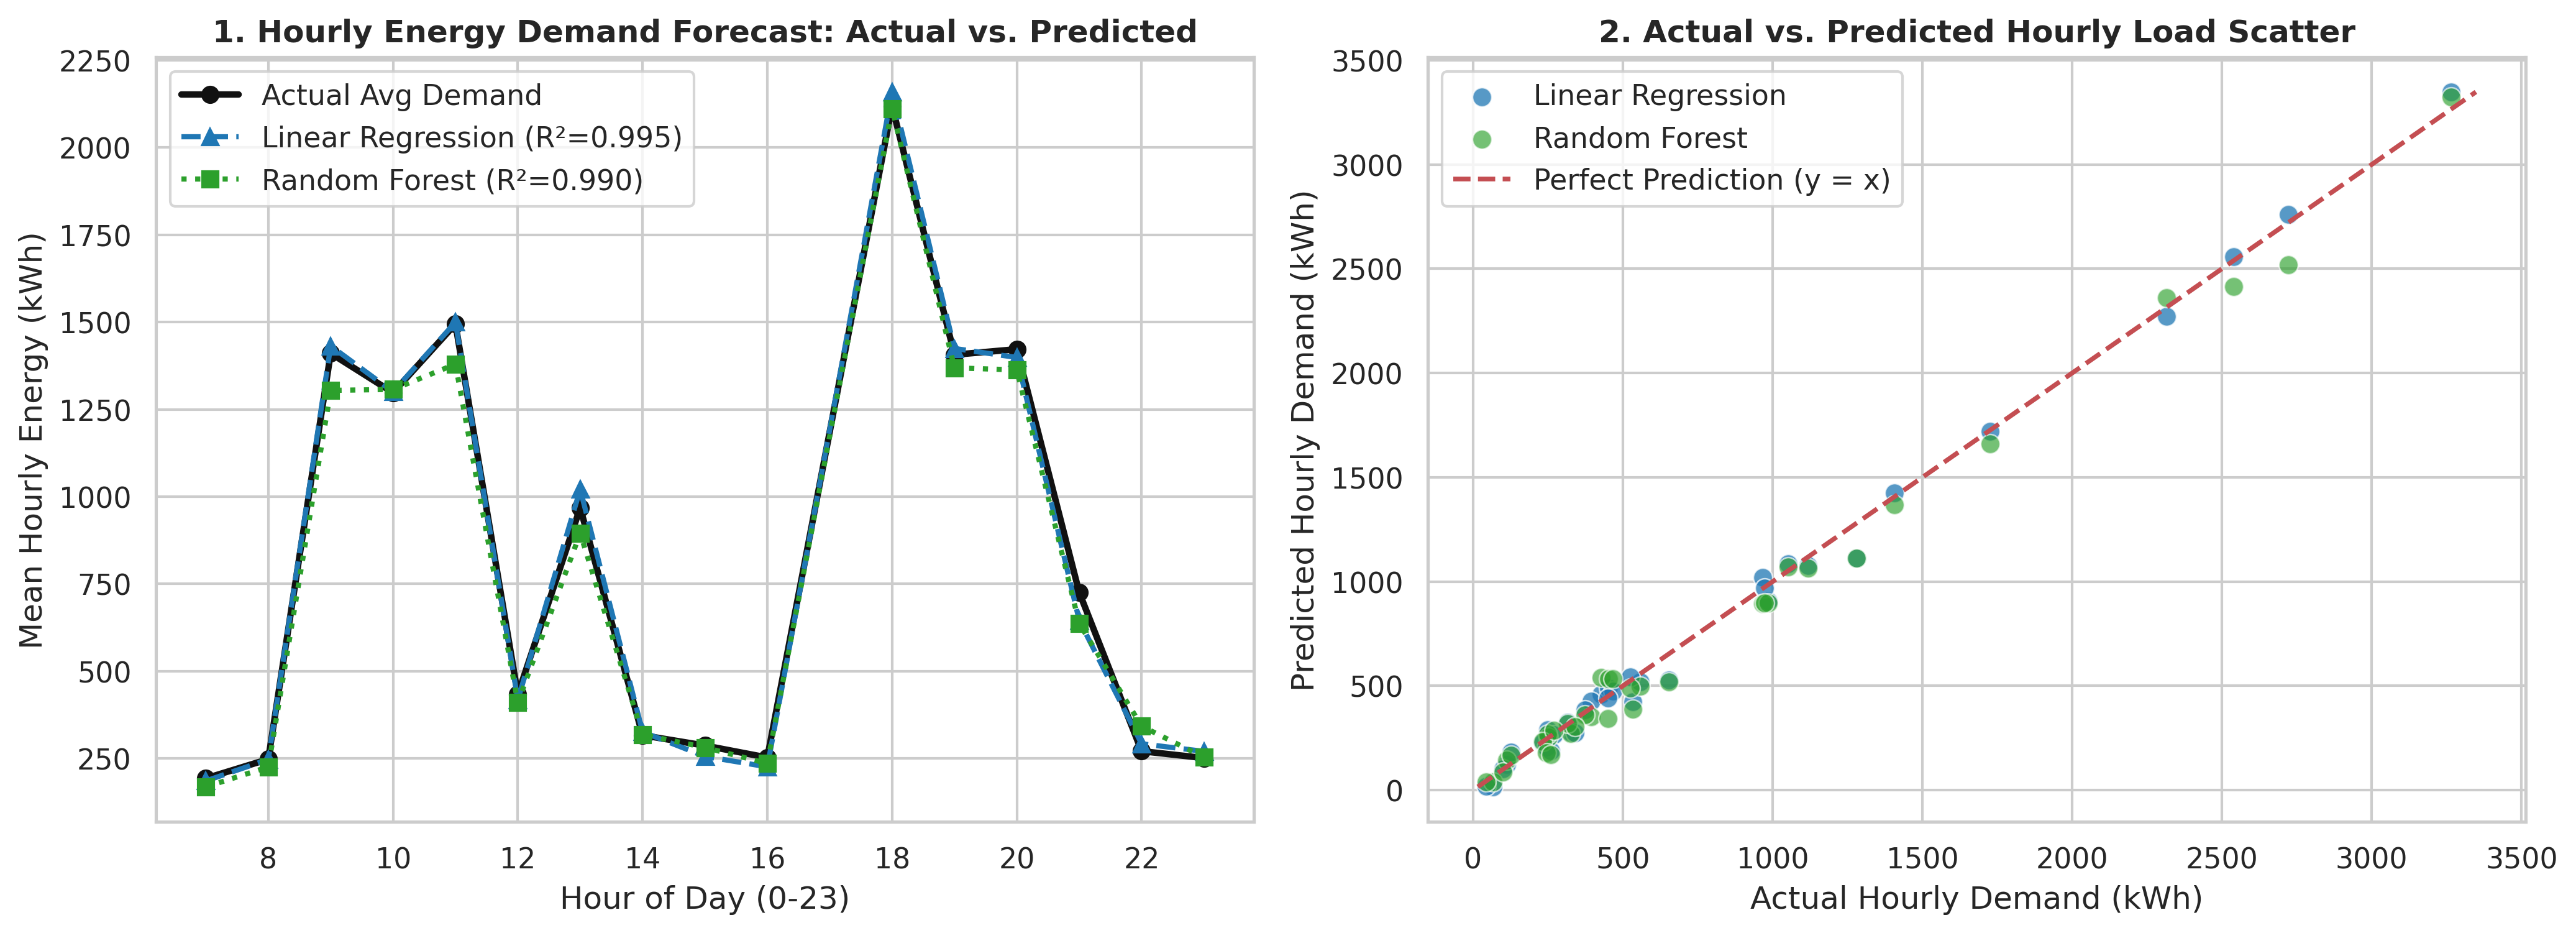

In [3]:
# Stage 8: Prediction Visualisation
from IPython.display import Image
Image('ev_prediction_visuals.png')